# Ensemble Learning Dashboard: Next-Day Temperature Forecasting for Sri Lankan Districts

---

### ⚠️ Declaration of AI Usage
**Declaration:**  
This assignment and its code (including data preprocessing, ensemble modeling, and the Streamlit dashboard) were developed with the assistance of **Claude (Anthropic)** for code structuring, implementation assistance, and debugging. All models, evaluations, and outputs were verified, tested, and validated by me.

---

## 1. Problem statement and dataset
**Goal:** predict the **next-day mean temperature (°C)** for six Sri Lankan districts: Colombo, Kandy, Galle, Jaffna, Anuradhapura and Nuwara Eliya. These districts span the wet zone, the dry zone, the northern peninsula and the central hill country, so the climates differ a lot.

**Data:** daily weather for 2015-2025 downloaded with `download_data.py` from the Open-Meteo historical API (ERA5 reanalysis) using each district's coordinates. These are reanalysis values for Sri Lankan locations, **not raw weather-station readings**, which is a limitation I acknowledge.

**Task type:** regression. **Metrics:** RMSE, MAE and R². **Split:** chronological. Train = 2015-2023, Test = 2024-2025, so we never train on the future.


In [ ]:
import warnings, os, json, time
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.ensemble import (RandomForestRegressor, ExtraTreesRegressor, AdaBoostRegressor,
                              GradientBoostingRegressor, StackingRegressor)
from sklearn.linear_model import Ridge, RidgeCV
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import KFold
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor
from statsmodels.tsa.arima.model import ARIMA

from ensemble_utils import (DISTRICTS, RAW_NUM, FEATURE_COLS, TARGET, add_features, ResidualHybrid)

RANDOM_STATE = 42
os.makedirs("models", exist_ok=True)

## 2. Load and clean the data

In [ ]:
raw = pd.read_csv("sri_lanka_weather.csv", parse_dates=["date"])
print("Shape:", raw.shape)
print("Date range:", raw["date"].min().date(), "to", raw["date"].max().date())
print("Districts:", raw["district"].unique().tolist())
raw.head()

Shape: (24108, 12)
Date range: 2015-01-01 to 2025-12-31
Districts: ['Colombo', 'Kandy', 'Galle', 'Jaffna', 'Anuradhapura', 'Nuwara Eliya']


,date,temperature_2m_max,temperature_2m_min,temperature_2m_mean,precipitation_sum,wind_speed_10m_max,wind_gusts_10m_max,shortwave_radiation_sum,et0_fao_evapotranspiration,district,latitude,longitude
0,2015-01-01,28.4,23.2,25.8,1.4,11.4,27.4,18.30,3.51,Colombo,6.9271,79.8612
1,2015-01-02,28.8,22.9,25.5,0.0,9.6,22.0,19.63,3.95,Colombo,6.9271,79.8612
2,2015-01-03,29.9,20.9,25.6,0.0,9.9,20.2,22.94,4.59,Colombo,6.9271,79.8612
3,2015-01-04,29.8,23.2,26.1,0.0,8.8,20.9,18.36,3.78,Colombo,6.9271,79.8612
4,2015-01-05,29.6,23.0,26.4,0.4,7.9,19.4,19.99,4.06,Colombo,6.9271,79.8612


In [ ]:
# --- Cleaning checks ---
df = raw.copy()
print("Duplicate (district, date) rows:", df.duplicated(["district", "date"]).sum())
df = df.drop_duplicates(["district", "date"])
print("Missing values:", int(df[RAW_NUM].isna().sum().sum()))

# Physical sanity checks
print("Negative rainfall rows:", int((df["precipitation_sum"] < 0).sum()))
print("Rows where Tmin > Tmax:", int((df["temperature_2m_min"] > df["temperature_2m_max"]).sum()))

# Drop columns that carry no information (constant per district, replaced by one-hot district)
df = df.drop(columns=["latitude", "longitude"])

# Check each district has a complete daily series (needed for lags and ARMA)
print(df.groupby("district")["date"].agg(["min", "max", "count"]))
df.describe().T.round(2)

Duplicate (district, date) rows: 0
Missing values: 0
Negative rainfall rows: 0
Rows where Tmin > Tmax: 0
                    min        max  count
district                                 
Anuradhapura 2015-01-01 2025-12-31   4018
Colombo      2015-01-01 2025-12-31   4018
Galle        2015-01-01 2025-12-31   4018
Jaffna       2015-01-01 2025-12-31   4018
Kandy        2015-01-01 2025-12-31   4018
Nuwara Eliya 2015-01-01 2025-12-31   4018


,count,mean,min,25%,50%,75%,max,std
date,24108,2020-07-01 12:00:00,2015-01-01 00:00:00,2017-10-01 00:00:00,2020-07-01 12:00:00,2023-04-02 00:00:00,2025-12-31 00:00:00,NaN
temperature_2m_max,24108.0,28.003563,14.7,27.2,28.9,30.5,37.7,4.134245
temperature_2m_min,24108.0,22.102501,4.8,20.9,23.5,25.0,30.1,4.457956
temperature_2m_mean,24108.0,24.645877,11.3,23.8,26.0,27.3,32.3,4.142691
precipitation_sum,24108.0,5.71115,0.0,0.4,2.1,6.9,308.5,10.320173
wind_speed_10m_max,24108.0,17.43033,2.5,12.3,16.8,21.6,46.9,6.776911
wind_gusts_10m_max,24108.0,39.508765,13.0,30.2,37.4,47.2,110.9,12.507694
shortwave_radiation_sum,24108.0,18.968543,1.21,16.51,19.68,22.12,29.41,4.325699
et0_fao_evapotranspiration,24108.0,3.978698,0.47,3.27,4.0,4.72,7.46,1.068116


## 3. Exploratory analysis

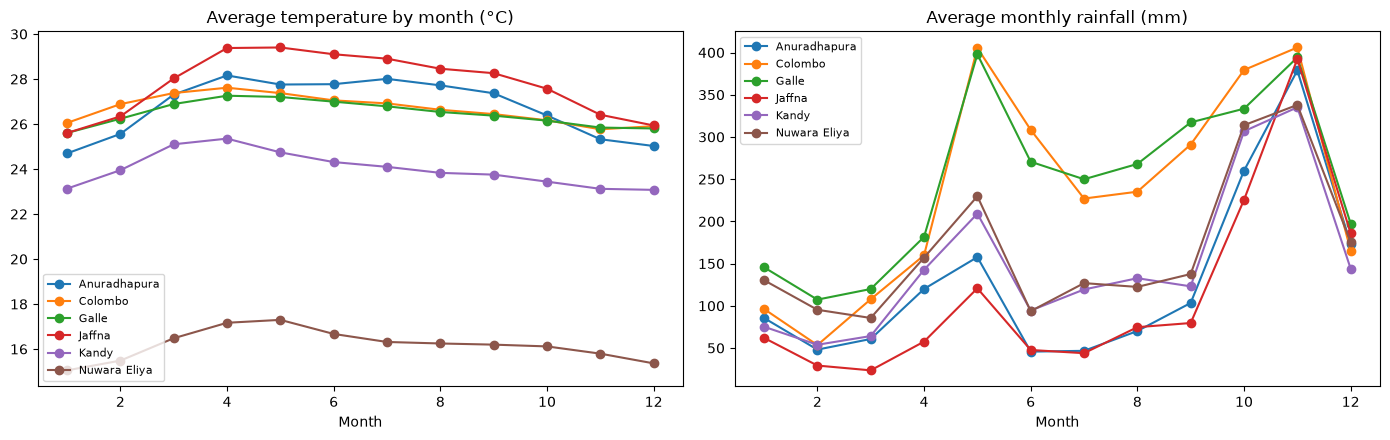

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
monthly_temp = df.assign(month=df["date"].dt.month).groupby(["month", "district"])["temperature_2m_mean"].mean().unstack()
monthly_temp.plot(ax=axes[0], marker="o")
axes[0].set_title("Average temperature by month (°C)"); axes[0].set_xlabel("Month"); axes[0].legend(fontsize=8)

monthly_rain = df.assign(ym=df["date"].dt.to_period("M"), month=df["date"].dt.month).groupby(["ym", "month", "district"])["precipitation_sum"].sum().reset_index()
monthly_rain = monthly_rain.groupby(["month", "district"])["precipitation_sum"].mean().unstack()
monthly_rain.plot(ax=axes[1], marker="o")
axes[1].set_title("Average monthly rainfall (mm)"); axes[1].set_xlabel("Month"); axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

**What to notice:** Nuwara Eliya (hill country) is much cooler than the lowland districts, and the monthly rainfall curves show the two monsoon seasons (the Yala and Maha rains). Wet-zone Colombo and Galle get far more rain than dry-zone Anuradhapura and Jaffna. This is why the **district** and **time of year** features matter.

## 4. Feature engineering and target
- **Target:** next-day mean temperature (`target_temp_next_day`), made by shifting the temperature series by -1 day within each district.
- **Lag features:** temperature 1, 2 and 3 days ago.
- **Rolling features:** 7-day average temperature and 7-day total rainfall.
- **Seasonality:** day-of-year encoded as sine and cosine, so 31 December is close to 1 January.
- **Regional categorical:** one-hot encoding of the six districts.

In [ ]:
feat = add_features(df)

# Last day of every district has features but no target: keep it as "latest known conditions" for the dashboard.
latest = feat.groupby("district").tail(1).copy()
latest.to_csv("models/latest_by_district.csv", index=False)

model_df = feat.dropna(subset=FEATURE_COLS + [TARGET]).sort_values(["date", "district"]).reset_index(drop=True)  # sorted by date so blocked CV folds are time blocks containing ALL districts
print("Modelling rows:", len(model_df), "| Features:", len(FEATURE_COLS))

SPLIT_DATE = pd.Timestamp("2024-01-01")
train = model_df[model_df["date"] < SPLIT_DATE]
test = model_df[model_df["date"] >= SPLIT_DATE]
X_train, y_train = train[FEATURE_COLS], train[TARGET]
X_test, y_test = test[FEATURE_COLS], test[TARGET]
print("Train:", X_train.shape, "| Test:", X_test.shape)

Modelling rows: 24066 | Features: 21
Train: (19686, 21) | Test: (4380, 21)


## 5. Evaluation helper and baselines

In [ ]:
results = []
preds = {}
trained = {}

def evaluate(name, family, y_pred, fit_seconds=None):
    rmse = float(np.sqrt(mean_squared_error(y_test, y_pred)))
    mae = float(mean_absolute_error(y_test, y_pred))
    r2 = float(r2_score(y_test, y_pred))
    results.append({"Model": name, "Family": family, "RMSE": round(rmse, 4), "MAE": round(mae, 4),
                    "R2": round(r2, 4), "Fit time (s)": None if fit_seconds is None else round(fit_seconds, 1)})
    preds[name] = np.asarray(y_pred)
    print(f"{name:<28} RMSE={rmse:.4f}  MAE={mae:.4f}  R2={r2:.4f}")

def fit_eval(name, family, model):
    t0 = time.time()
    model.fit(X_train, y_train)
    secs = time.time() - t0
    evaluate(name, family, model.predict(X_test), secs)
    trained[name] = model
    return model

# Baseline 1: persistence ("tomorrow = today")
evaluate("Baseline: Persistence", "Baseline", X_test["temperature_2m_mean"].values)
# Baseline 2: Ridge regression (a single linear model)
fit_eval("Baseline: Ridge", "Baseline", make_pipeline(StandardScaler(), Ridge(alpha=1.0)))

Baseline: Persistence        RMSE=0.5855  MAE=0.4450  R2=0.9815
Baseline: Ridge              RMSE=0.5501  MAE=0.4265  R2=0.9837


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('ridge', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](21,)","['temperature_2m_max','temperature_2m_min','temperature_2m_mean',..., 'district_Jaffna','district_Anuradhapura','district_Nuwara Eliya']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,21
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value


## 6. Bagging (bootstrap aggregation)
Bagging trains many deep trees on **bootstrap samples** and averages them, which mainly reduces **variance**. At each split a Random Forest also considers only a random subset of features, so the trees are decorrelated. The **out-of-bag (OOB)** samples (about 37% of rows left out of each bootstrap) give a built-in validation estimate.

In [ ]:
rf = RandomForestRegressor(n_estimators=300, min_samples_leaf=2, max_features=0.5,
                           oob_score=True, n_jobs=-1, random_state=RANDOM_STATE)
fit_eval("Random Forest", "Bagging", rf)
print("RF OOB R2 (train):", round(rf.oob_score_, 4))
fit_eval("Extra Trees", "Bagging", ExtraTreesRegressor(n_estimators=300, min_samples_leaf=2, max_features=0.5,
                                                        n_jobs=-1, random_state=RANDOM_STATE))

Random Forest                RMSE=0.5516  MAE=0.4301  R2=0.9836
RF OOB R2 (train): 0.987
Extra Trees                  RMSE=0.5511  MAE=0.4312  R2=0.9836


,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",300
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",2
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",0.5
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls 3 sources of randomness:- the bootstrapping of the samples used when building trees (if ``bootstrap=True``)- the sampling of the features to consider when looking for the best split at each node (if ``max_features < n_features``)- the draw of the splits for each of the `max_features`See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not p

*Note:* the OOB score is computed on random bootstrap holdouts from the training years, so it can look better than the chronological test score. Neighbouring days are strongly correlated, which is why I rely on the chronological test split as the honest estimate.

## 7. Boosting
Boosting builds models **sequentially**, and each new model focuses on the errors of the previous ones, which mainly reduces **bias**.
- **AdaBoost:** re-weights hard samples. **Gradient Boosting:** fits each new tree to the residuals (negative gradient of the loss).
- **XGBoost, LightGBM, CatBoost:** optimised gradient-boosting libraries (regularisation, histogram splits, leaf-wise growth for LightGBM, ordered boosting for CatBoost).

In [ ]:
from sklearn.tree import DecisionTreeRegressor
fit_eval("AdaBoost", "Boosting", AdaBoostRegressor(estimator=DecisionTreeRegressor(max_depth=4),
                                                    n_estimators=200, learning_rate=0.05, random_state=RANDOM_STATE))
fit_eval("Gradient Boosting", "Boosting", GradientBoostingRegressor(n_estimators=300, learning_rate=0.05,
                                                                     max_depth=4, subsample=0.8, random_state=RANDOM_STATE))
fit_eval("XGBoost", "Boosting", XGBRegressor(n_estimators=400, learning_rate=0.05, max_depth=5,
                                              subsample=0.8, colsample_bytree=0.8, n_jobs=-1, random_state=RANDOM_STATE))
fit_eval("LightGBM", "Boosting", LGBMRegressor(n_estimators=400, learning_rate=0.05, num_leaves=31,
                                                subsample=0.8, colsample_bytree=0.8, n_jobs=-1,
                                                random_state=RANDOM_STATE, verbose=-1))
fit_eval("CatBoost", "Boosting", CatBoostRegressor(iterations=500, learning_rate=0.05, depth=6,
                                                    random_seed=RANDOM_STATE, verbose=0))

AdaBoost                     RMSE=0.5854  MAE=0.4586  R2=0.9815
Gradient Boosting            RMSE=0.5451  MAE=0.4245  R2=0.9840
XGBoost                      RMSE=0.5448  MAE=0.4242  R2=0.9840
LightGBM                     RMSE=0.5449  MAE=0.4242  R2=0.9840
CatBoost                     RMSE=0.5507  MAE=0.4297  R2=0.9837


CatBoostRegressor(depth=6, iterations=500, learning_rate=0.05, loss_function='RMSE', random_seed=42, verbose=0)

## 8. Stacking
Stacking combines **different kinds of models**. Level-0 base learners are Random Forest (bagging), XGBoost (boosting) and an ANN (neural network). A Level-1 **meta-learner** (Ridge regression) learns how to weight their predictions. Scikit-learn's `StackingRegressor` builds the meta-learner's training data from **out-of-fold predictions** (5 blocked folds; the training rows are sorted by date, so each fold is a contiguous block of time covering all districts), which prevents the leakage you would get by training the meta-learner on predictions the base models made for their own training rows.

In [ ]:
ann = make_pipeline(StandardScaler(), MLPRegressor(hidden_layer_sizes=(64, 32), early_stopping=True,
                                                    max_iter=500, random_state=RANDOM_STATE))
stack = StackingRegressor(
    estimators=[
        ("rf", RandomForestRegressor(n_estimators=150, min_samples_leaf=2, max_features=0.5, n_jobs=-1, random_state=RANDOM_STATE)),
        ("xgb", XGBRegressor(n_estimators=300, learning_rate=0.05, max_depth=5, subsample=0.8, n_jobs=-1, random_state=RANDOM_STATE)),
        ("ann", ann),
    ],
    final_estimator=RidgeCV(), cv=KFold(n_splits=5, shuffle=False), n_jobs=1)
fit_eval("Stacking (RF+XGB+ANN -> Ridge)", "Stacking", stack)
print("Meta-learner weights:", dict(zip(["rf", "xgb", "ann"], stack.final_estimator_.coef_.round(3))))

Stacking (RF+XGB+ANN -> Ridge) RMSE=0.5430  MAE=0.4224  R2=0.9841
Meta-learner weights: {'rf': np.float64(0.229), 'xgb': np.float64(0.683), 'ann': np.float64(0.086)}


## 9. Hybrid models
Hybrids couple model families that capture **different structure** in the data.

**(a) RF + ANN (residual hybrid):** an ANN learns the smooth main relationship, then a Random Forest learns the ANN's **residuals** (the non-linear structure the ANN missed). Prediction = ANN + RF-on-residuals.

In [ ]:
hyb_rf_ann = ResidualHybrid(base_model=ann,
                            residual_model=RandomForestRegressor(n_estimators=200, min_samples_leaf=3,
                                                                 max_features=0.5, n_jobs=-1, random_state=RANDOM_STATE))
fit_eval("Hybrid RF + ANN", "Hybrid", hyb_rf_ann)

Hybrid RF + ANN              RMSE=0.5752  MAE=0.4352  R2=0.9822


,base_model,Pipeline(step...m_state=42))])
,residual_model,RandomForestR...ndom_state=42)
Name,Type,Value
base_,Pipeline,Pipeline(step...m_state=42))])
resid_,RandomForestRegressor,RandomForestR...ndom_state=42)
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
,"hidden_layer_sizes hidden_layer_sizes: array-like of shape(n_layers - 2,), default=(100,)The ith element represents the number of neurons in the ithhidden layer.","(64, ...)"
,"max_iter max_iter: int, default=200Maximum number of iterations. The solver iterates until convergence(determined by 'tol') or this number of iterations. For stochasticsolvers ('sgd', 'adam'), note that this determines the number of epochs(how many times each data point will be used), not the number ofgradient steps.",500
,"random_state random_state: int, RandomState instance, default=NoneDetermines random number generation for weights and biasinitialization, train-test split if early stopping is used, and batchsampling when solver='sgd' or 'adam'.Pass an int for reproducible results across multiple function calls.See :term:`Glossary <random_state>`.",42


**(b) RF + ARMA (time-series hybrid):** an **ARMA(2,2)** model, fitted per district on the training years only, captures the **linear autocorrelation** of the temperature series. A Random Forest then models what ARMA leaves behind: the **non-linear residuals** driven by rainfall, wind, radiation and the season. Final prediction = ARMA forecast + RF residual prediction. ARMA parameters are fitted on training data only. For the test years I only *apply* the fixed parameters to the observed series to get one-step-ahead forecasts, so there is no leakage.

In [ ]:
arma_parts = []
for d in DISTRICTS:
    s = df[df["district"] == d].set_index("date")["temperature_2m_mean"].asfreq("D")
    s_train = s[s.index < SPLIT_DATE]
    arma_res = ARIMA(s_train, order=(2, 0, 2)).fit()          # ARMA(2,2) = ARIMA with d=0
    fitted_all = arma_res.apply(s).fittedvalues                # one-step-ahead prediction for each day
    nxt = fitted_all.shift(-1)                                 # prediction of tomorrow made at day t
    arma_parts.append(pd.DataFrame({"date": nxt.index, "district": d, "arma_next": nxt.values}))
arma_df = pd.concat(arma_parts)

m = model_df.merge(arma_df, on=["date", "district"], how="left")
tr, te = m[m["date"] < SPLIT_DATE], m[m["date"] >= SPLIT_DATE]
assert te["date"].tolist() == test["date"].tolist()   # same rows/order as the other models

# ARMA alone
evaluate("ARMA(2,2) alone", "Time series", te["arma_next"].values)

# RF on ARMA residuals (arma forecast is also given as a feature)
cols_h = FEATURE_COLS + ["arma_next"]
rf_resid = RandomForestRegressor(n_estimators=300, min_samples_leaf=3, max_features=0.5,
                                 n_jobs=-1, random_state=RANDOM_STATE)
t0 = time.time()
rf_resid.fit(tr[cols_h], tr[TARGET] - tr["arma_next"])
evaluate("Hybrid RF + ARMA", "Hybrid", te["arma_next"].values + rf_resid.predict(te[cols_h]), time.time() - t0)

ARMA(2,2) alone              RMSE=0.5515  MAE=0.4291  R2=0.9836
Hybrid RF + ARMA             RMSE=0.5407  MAE=0.4226  R2=0.9842


## 10. Comparison of all models

In [ ]:
res_df = pd.DataFrame(results).sort_values("RMSE").reset_index(drop=True)
res_df.to_csv("models/results.csv", index=False)
res_df

,Model,Family,RMSE,MAE,R2,Fit time (s)
0,Hybrid RF + ARMA,Hybrid,0.5407,0.4226,0.9842,5.6
1,Stacking (RF+XGB+ANN -> Ridge),Stacking,0.5430,0.4224,0.9841,22.7
2,XGBoost,Boosting,0.5448,0.4242,0.9840,0.6
3,LightGBM,Boosting,0.5449,0.4242,0.9840,1.4
4,Gradient Boosting,Boosting,0.5451,0.4245,0.9840,16.9
5,Baseline: Ridge,Baseline,0.5501,0.4265,0.9837,0.0
6,CatBoost,Boosting,0.5507,0.4297,0.9837,0.9
7,Extra Trees,Bagging,0.5511,0.4312,0.9836,1.8
8,"ARMA(2,2) alone",Time series,0.5515,0.4291,0.9836,NaN
9,Random Forest,Bagging,0.5516,0.4301,0.9836,4.5


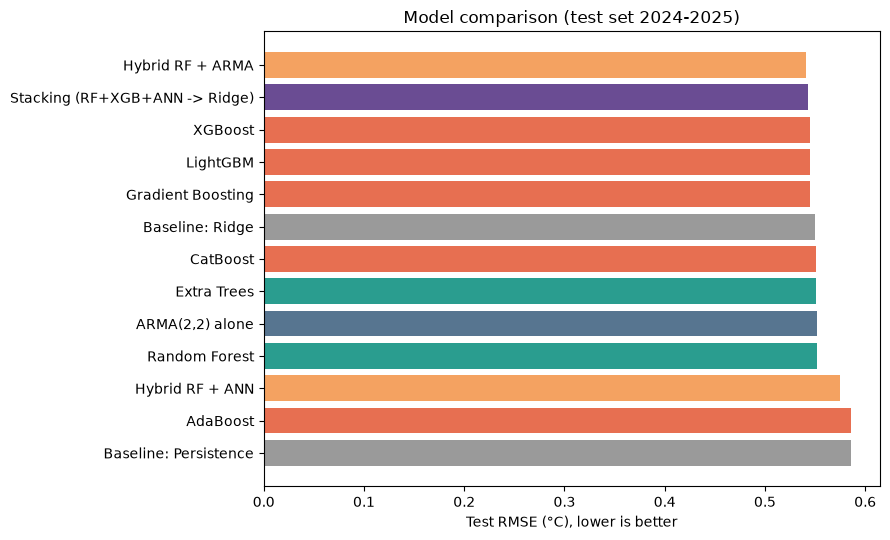

In [ ]:
colors = {"Bagging": "#2a9d8f", "Boosting": "#e76f51", "Stacking": "#6a4c93", "Hybrid": "#f4a261",
          "Baseline": "#9a9a9a", "Time series": "#577590"}
plot_df = res_df.sort_values("RMSE", ascending=False)
plt.figure(figsize=(9, 5.5))
plt.barh(plot_df["Model"], plot_df["RMSE"], color=[colors[f] for f in plot_df["Family"]])
plt.xlabel("Test RMSE (°C), lower is better"); plt.title("Model comparison (test set 2024-2025)")
plt.tight_layout(); plt.show()

Best model by RMSE: Hybrid RF + ARMA


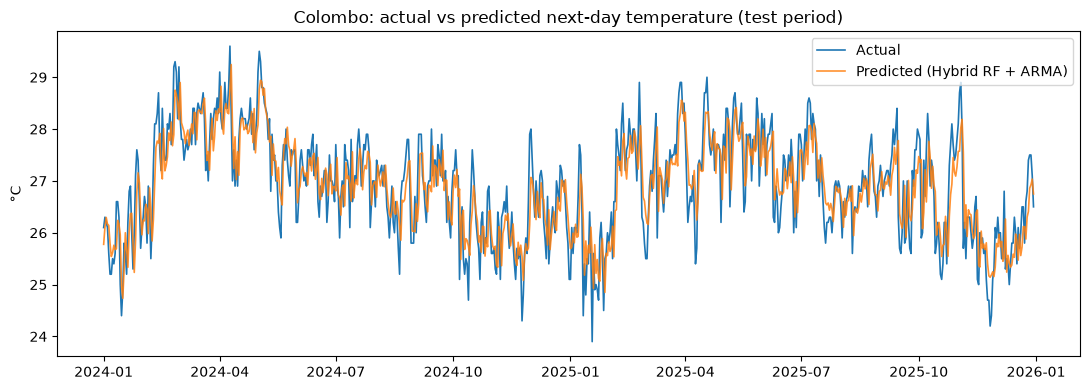

In [ ]:
best = res_df.iloc[0]["Model"]
print("Best model by RMSE:", best)
plt.figure(figsize=(11, 4))
mask = (test["district"] == "Colombo").values
plt.plot(test.loc[mask, "date"], y_test[mask], label="Actual", lw=1.2)
plt.plot(test.loc[mask, "date"], preds[best][mask], label=f"Predicted ({best})", lw=1.2, alpha=0.85)
plt.title("Colombo: actual vs predicted next-day temperature (test period)"); plt.ylabel("°C"); plt.legend()
plt.tight_layout(); plt.show()

In [ ]:
# Per-district error for a few key models (helps explain where the remaining error comes from)
names = list(dict.fromkeys([best, "Random Forest", "XGBoost", "Baseline: Persistence"]))
rows = []
for d in DISTRICTS:
    mk = (test["district"] == d).values
    r = {"District": d}
    for n in names:
        r[n] = round(float(np.sqrt(mean_squared_error(y_test[mk], preds[n][mk]))), 3)
    rows.append(r)
pd.DataFrame(rows).set_index("District")

,Hybrid RF + ARMA,Random Forest,XGBoost,Baseline: Persistence
District,,,,
Colombo,0.575,0.582,0.578,0.628
Kandy,0.531,0.540,0.529,0.567
Galle,0.566,0.572,0.567,0.639
Jaffna,0.506,0.537,0.520,0.542
Anuradhapura,0.578,0.583,0.584,0.608
Nuwara Eliya,0.480,0.490,0.484,0.519


### Interpretation of the comparison

**1. Everything beats nothing, but only a little.** The "tomorrow = today" persistence baseline already scores R² of about 0.98 (RMSE about 0.59 °C), because temperature changes slowly from one day to the next. The best model, **Hybrid RF + ARMA**, reaches an RMSE of about 0.54 °C, only about **7-8 % better than persistence**, and about 2 % better than the single linear Ridge model. The remaining error of roughly half a degree is mostly day-to-day weather variation that these features (one location's own recent history) cannot explain.

**2. The top models are very close.** Hybrid RF + ARMA, Stacking, XGBoost, LightGBM and Gradient Boosting all land between about 0.541 and 0.545 °C. Differences this small may not be meaningful; I did not run a statistical significance test, so I do not claim a clear winner among them.

**3. Boosting did slightly better than bagging.** Gradient Boosting, XGBoost and LightGBM (about 0.545) beat Random Forest and Extra Trees (about 0.551-0.552). A plausible reason is that boosting adds trees one after another to correct the previous errors, so it reduces *bias*, whereas bagging mainly reduces *variance* and this target has little variance to remove. Random Forest was even slightly behind plain Ridge regression: next-day temperature is almost a straight-line function of today's and the recent temperature, and trees approximate straight lines with steps and cannot extrapolate beyond the temperatures seen in training. AdaBoost was the weakest ensemble (about the same as persistence); its sample re-weighting with shallow trees and a small learning rate seems to under-fit this smooth problem.

**4. Stacking helped a little.** The meta-learner put most weight on XGBoost (about 0.68), then Random Forest (about 0.23) and the ANN (about 0.09). Stacking was about 0.3 % better than XGBoost alone, because the base models make similar mistakes and so there is little left for a combination to fix.

**5. Hybrids: one worked, one did not.** *RF + ARMA* improved on ARMA alone by about 2 %: ARMA captures the linear autocorrelation, and the Random Forest then picks up non-linear structure it missed (district differences, season, solar radiation). *RF + ANN* was worse than most models. The ANN is the weaker base learner, and the residuals of the training data are smaller than those on new data, so the second-stage forest learns corrections that do not transfer well. This is my interpretation, not something I tested directly.

**6. Where the error is.** The per-district table above shows whether some districts are harder to predict than others (see the numbers it prints).

## 11. Feature importance

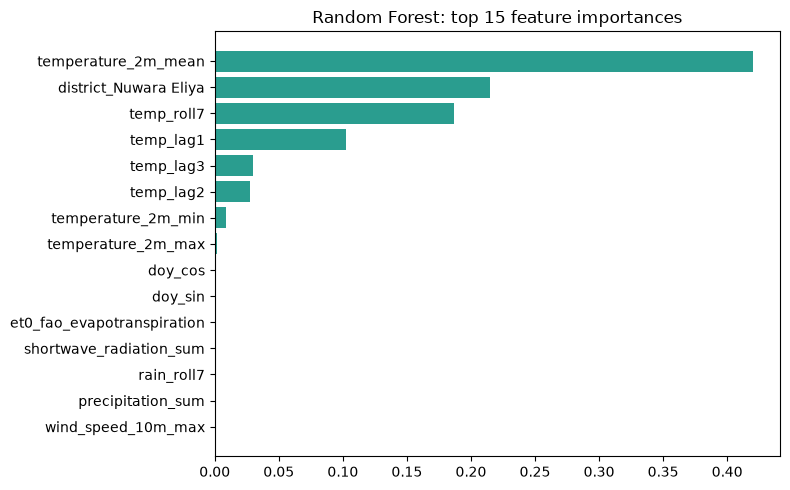

,Random Forest,Extra Trees,AdaBoost,Gradient Boosting,XGBoost,LightGBM,CatBoost
temperature_2m_mean,0.420,0.137,0.522,0.795,0.071,0.098,0.180
district_Nuwara Eliya,0.215,0.372,0.217,0.110,0.924,0.001,0.143
temp_roll7,0.187,0.119,0.236,0.088,0.003,0.050,0.087
temp_lag1,0.102,0.096,0.000,0.000,0.000,0.046,0.087
temp_lag3,0.030,0.079,0.002,0.002,0.000,0.048,0.184
temp_lag2,0.028,0.069,0.019,0.000,0.000,0.039,0.182
temperature_2m_min,0.009,0.058,0.001,0.000,0.000,0.054,0.067
temperature_2m_max,0.001,0.034,0.001,0.000,0.000,0.062,0.020
doy_cos,0.001,0.003,0.001,0.000,0.000,0.077,0.007
doy_sin,0.001,0.001,0.000,0.000,0.000,0.097,0.004


In [ ]:
tree_models = ["Random Forest", "Extra Trees", "AdaBoost", "Gradient Boosting", "XGBoost", "LightGBM", "CatBoost"]
imp = {}
for n in tree_models:
    mdl = trained[n]
    v = np.asarray(mdl.feature_importances_, dtype=float)
    imp[n] = v / v.sum()
imp_df = pd.DataFrame(imp, index=FEATURE_COLS)
imp_df.to_csv("models/feature_importances.csv")

top = imp_df["Random Forest"].sort_values().tail(15)
plt.figure(figsize=(8, 5)); plt.barh(top.index, top.values, color="#2a9d8f")
plt.title("Random Forest: top 15 feature importances"); plt.tight_layout(); plt.show()
imp_df.sort_values("Random Forest", ascending=False).head(10).round(3)

### Interpretation of the feature importance
- **Today's mean temperature dominates**, followed by the **Nuwara Eliya district flag**, the **7-day average temperature** and the **1-day lag**. This makes physical sense: tomorrow's temperature is mostly today's temperature, and the hill-country district is about 8-10 °C cooler than the lowland districts, so knowing it is Nuwara Eliya is a huge clue about the temperature *level*.
- **Rainfall, wind, solar radiation and evapotranspiration have almost no importance** for next-day *temperature*. They would matter more if we predicted rainfall.
- Today's max, min and the lags are strongly correlated with today's mean, so they share importance; impurity-based importance can therefore under-state some of them. Treat the chart as a rough guide.

## 12. Save models and files for the dashboard

In [ ]:
# Hybrid RF+ARMA is evaluated here but not saved for live inference (it needs the full daily history to compute the ARMA forecast).
for name, mdl in trained.items():
    safe = name.replace(" ", "_").replace("(", "").replace(")", "").replace("+", "").replace("->", "to").replace(":", "")
    joblib.dump(mdl, f"models/{safe}.joblib")

# Test-set predictions (for the dashboard's actual-vs-predicted chart)
pred_out = test[["date", "district"]].copy()
pred_out["actual"] = y_test.values
for n, p in preds.items():
    pred_out[n] = p
pred_out.to_csv("models/test_predictions.csv", index=False)

# Name map: display name -> file
name_map = {n: n.replace(" ", "_").replace("(", "").replace(")", "").replace("+", "").replace("->", "to").replace(":", "") + ".joblib"
            for n in trained}
json.dump({"name_map": name_map, "feature_cols": FEATURE_COLS}, open("models/meta.json", "w"), indent=2)
print(sorted(os.listdir("models")))

['AdaBoost.joblib', 'Baseline_Ridge.joblib', 'CatBoost.joblib', 'Extra_Trees.joblib', 'Gradient_Boosting.joblib', 'Hybrid_RF__ANN.joblib', 'LightGBM.joblib', 'Random_Forest.joblib', 'Stacking_RFXGBANN_to_Ridge.joblib', 'XGBoost.joblib', 'feature_importances.csv', 'latest_by_district.csv', 'meta.json', 'results.csv', 'test_predictions.csv']


## 13. Conclusions and limitations
- All ensemble methods predicted next-day temperature well (R² about 0.98, RMSE about 0.54-0.55 °C), but because the problem is smooth and strongly autocorrelated, even the persistence baseline and Ridge regression are strong. The ensembles gave a modest gain of about 7-8 % in RMSE over persistence.
- **Hybrid RF + ARMA** was the best model, followed closely by **Stacking** and the **boosting** methods (XGBoost, LightGBM, Gradient Boosting). Bagging (Random Forest, Extra Trees) was slightly behind boosting, and **RF + ANN** and **AdaBoost** were the weakest.
- The most useful features were today's temperature, the district (especially cool Nuwara Eliya) and recent temperature history.
- **Limitations:** the data are ERA5 reanalysis values for district coordinates, not raw station observations; only one-day-ahead forecasting; hyper-parameters were set by hand without extensive tuning; I did not test whether small differences between the top models are statistically significant.
- **Future work:** add Department of Meteorology station data, add humidity, pressure and neighbouring-district features, tune with time-series cross-validation, and add a rainfall-occurrence classifier.

**Dashboard:** run `streamlit run app.py` (see the video for a live demonstration).